# Flowboard Product Analytics

## 1. Metric System and Definitions

This analysis examines product activation, retention, funnel
conversion, experiment outcomes and user behaviour.

Metric definitions are documented in `metric_definitions.md`.

All timestamps use UTC.

In [1]:
%pip install -q google-cloud-bigquery db-dtypes scipy statsmodels seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from google.cloud import bigquery

client = bigquery.Client(project="product-analysis-509809")

activation = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_activation`
    ORDER BY acquisition_channel
""").to_dataframe()

display(activation)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,acquisition_channel,total_signups,d7_observable_users,activated_d7_users,not_activated_d7_users,users_with_observed_activation_time,avg_time_to_activate_days,median_time_to_activate_days,p90_time_to_activate_days,under_1_day,...,days_7_to_14,days_14_to_31,days_31_plus,d7_activation_rate_pct,under_1_day_pct,days_1_to_3_pct,days_3_to_7_pct,days_7_to_14_pct,days_14_to_31_pct,days_31_plus_pct
0,content,7449,7449,2696,4753,5031,23.493854,5.238704,78.141389,1939,...,611,479,1245,36.19,38.54,5.59,9.46,12.14,9.52,24.75
1,direct,7470,7470,2551,4919,4997,24.804360,6.247674,81.334595,1874,...,681,486,1279,34.15,37.50,4.94,8.61,13.63,9.73,25.60
2,organic_search,12145,12145,4581,7564,8658,22.632542,5.857350,73.863542,3327,...,1135,862,2080,37.72,38.43,5.29,9.19,13.11,9.96,24.02
3,paid_search,8929,8929,2493,6436,5096,27.470441,7.692454,88.125949,1814,...,597,544,1462,27.92,35.60,5.12,8.20,11.72,10.68,28.69
4,partner,4922,4922,1874,3048,3521,22.713260,5.578021,73.002060,1372,...,453,342,852,38.07,38.97,5.23,9.03,12.87,9.71,24.20
5,referral,9085,9085,3970,5115,7031,20.091502,4.069757,67.032940,2983,...,894,677,1490,43.70,42.43,4.89,9.15,12.72,9.63,21.19


,acquisition_channel,total_signups,activated_d7_users,d7_activation_rate_pct,median_time_to_activate_days,p90_time_to_activate_days
5,referral,9085,3970,43.70,4.069757,67.032940
4,partner,4922,1874,38.07,5.578021,73.002060
2,organic_search,12145,4581,37.72,5.857350,73.863542
0,content,7449,2696,36.19,5.238704,78.141389
1,direct,7470,2551,34.15,6.247674,81.334595
3,paid_search,8929,2493,27.92,7.692454,88.125949


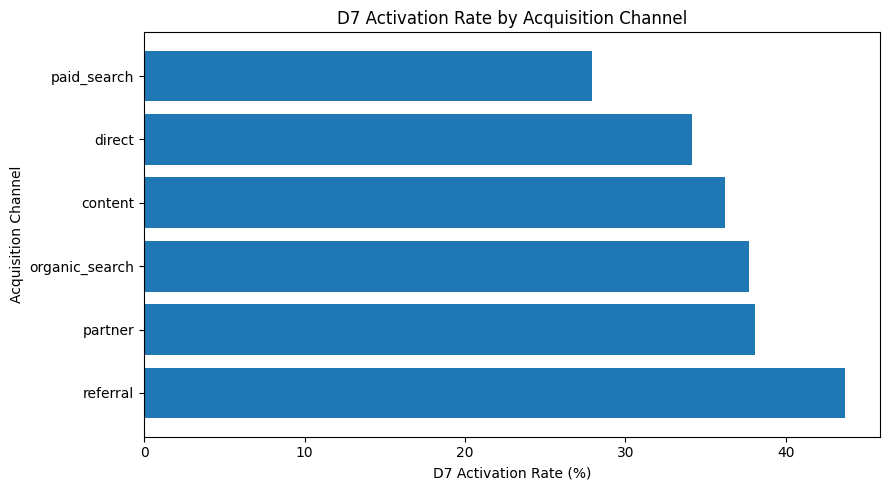

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
activation_summary = activation[
    [
        "acquisition_channel",
        "total_signups",
        "activated_d7_users",
        "d7_activation_rate_pct",
        "median_time_to_activate_days",
        "p90_time_to_activate_days"
    ]
].sort_values("d7_activation_rate_pct", ascending=False)

display(activation_summary)

plt.figure(figsize=(9, 5))
plt.barh(
    activation_summary["acquisition_channel"],
    activation_summary["d7_activation_rate_pct"]
)
plt.xlabel("D7 Activation Rate (%)")
plt.ylabel("Acquisition Channel")
plt.title("D7 Activation Rate by Acquisition Channel")
plt.tight_layout()
plt.show()

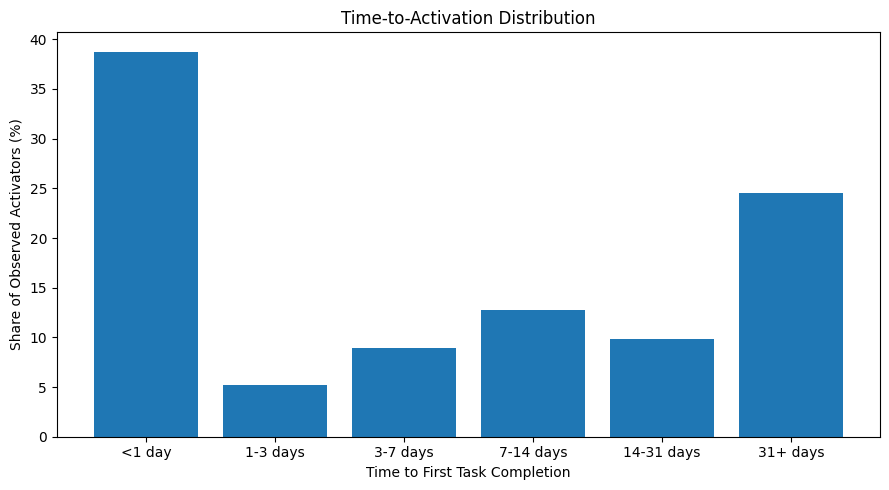

In [3]:
bucket_columns = [
    "under_1_day",
    "days_1_to_3",
    "days_3_to_7",
    "days_7_to_14",
    "days_14_to_31",
    "days_31_plus"
]

bucket_labels = [
    "<1 day",
    "1-3 days",
    "3-7 days",
    "7-14 days",
    "14-31 days",
    "31+ days"
]

bucket_totals = activation[bucket_columns].sum()
total_activators = bucket_totals.sum()

bucket_percentages = bucket_totals / total_activators * 100

plt.figure(figsize=(9, 5))
plt.bar(bucket_labels, bucket_percentages)
plt.xlabel("Time to First Task Completion")
plt.ylabel("Share of Observed Activators (%)")
plt.title("Time-to-Activation Distribution")
plt.tight_layout()
plt.show()

In [4]:
retention = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_retention`
    ORDER BY signup_cohort_month, activation_status
""").to_dataframe()

display(retention)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,signup_cohort_month,activation_status,cohort_users,d1_retained_users,d1_retention_rate,d7_retained_users,d7_retention_rate,d30_retained_users,d30_retention_rate
0,2026-01-01,activated_d7,2625,305,11.62,218,8.30,65,2.48
1,2026-01-01,not_activated_d7,4647,139,2.99,181,3.89,76,1.64
2,2026-02-01,activated_d7,2452,285,11.62,203,8.28,53,2.16
3,2026-02-01,not_activated_d7,4252,135,3.17,170,4.00,69,1.62
4,2026-03-01,activated_d7,2644,306,11.57,224,8.47,72,2.72
5,2026-03-01,not_activated_d7,4615,148,3.21,202,4.38,77,1.67
6,2026-04-01,activated_d7,2626,295,11.23,239,9.10,71,2.70
7,2026-04-01,not_activated_d7,4564,152,3.33,201,4.40,92,2.02
8,2026-05-01,activated_d7,2663,321,12.05,229,8.60,58,2.18
9,2026-05-01,not_activated_d7,4736,158,3.34,212,4.48,65,1.37


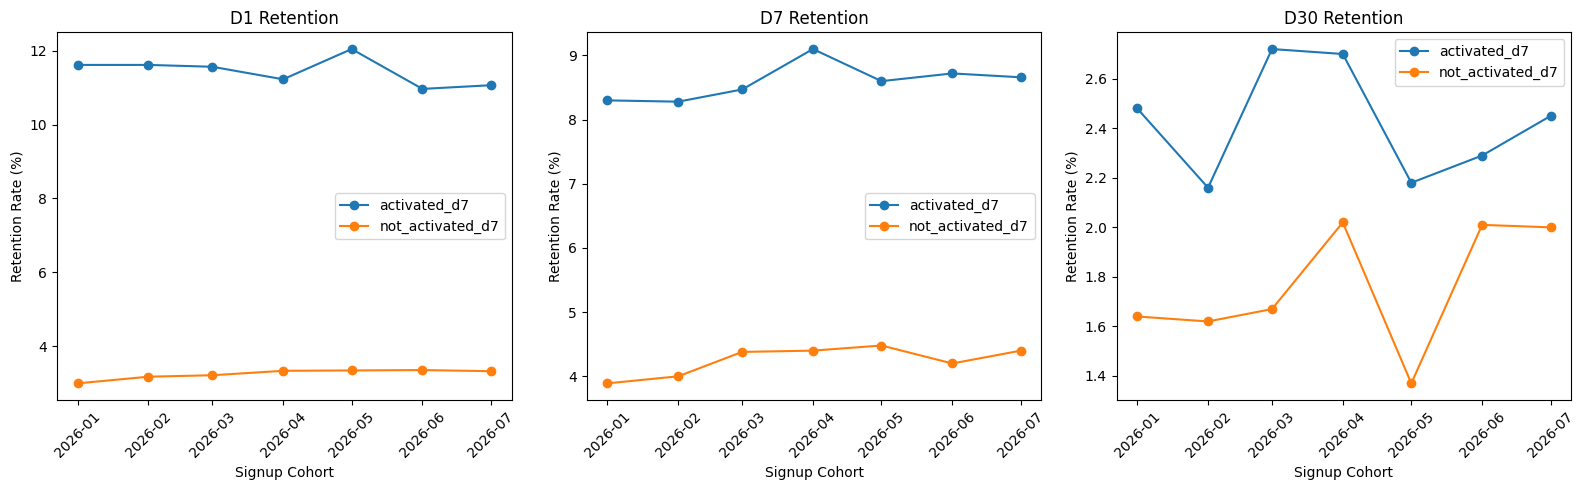

In [5]:
retention["signup_cohort_month"] = pd.to_datetime(
    retention["signup_cohort_month"]
)

metrics = [
    ("d1_retention_rate", "D1 Retention"),
    ("d7_retention_rate", "D7 Retention"),
    ("d30_retention_rate", "D30 Retention")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (metric, title) in zip(axes, metrics):
    for status, group in retention.groupby("activation_status"):
        group = group.sort_values("signup_cohort_month")

        ax.plot(
            group["signup_cohort_month"],
            group[metric],
            marker="o",
            label=status
        )

    ax.set_title(title)
    ax.set_ylabel("Retention Rate (%)")
    ax.set_xlabel("Signup Cohort")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.tight_layout()
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt

funnel = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_funnel`
    ORDER BY total_signups DESC
""").to_dataframe()

display(funnel)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,acquisition_channel,total_signups,signup_completed_users,signup_completion_dropoff_users,signup_completion_conversion_rate_pct,project_created_users,project_creation_dropoff_users,project_creation_conversion_rate_pct,task_created_users,task_creation_dropoff_users,task_creation_conversion_rate_pct,task_completed_users,task_completion_dropoff_users,task_completion_conversion_rate_pct,overall_signup_to_task_completion_rate_pct
0,organic_search,12145,12145,0,100.0,11318,827,93.19,9821,1497,86.77,8653,1168,88.11,71.25
1,referral,9085,9085,0,100.0,8702,383,95.78,7801,901,89.65,7028,773,90.09,77.36
2,paid_search,8929,8929,0,100.0,7621,1308,85.35,6121,1500,80.32,5096,1025,83.25,57.07
3,direct,7470,7470,0,100.0,6810,660,91.16,5768,1042,84.70,4994,774,86.58,66.85
4,content,7449,7449,0,100.0,6769,680,90.87,5789,980,85.52,5031,758,86.91,67.54
5,partner,4922,4922,0,100.0,4608,314,93.62,3959,649,85.92,3521,438,88.94,71.54


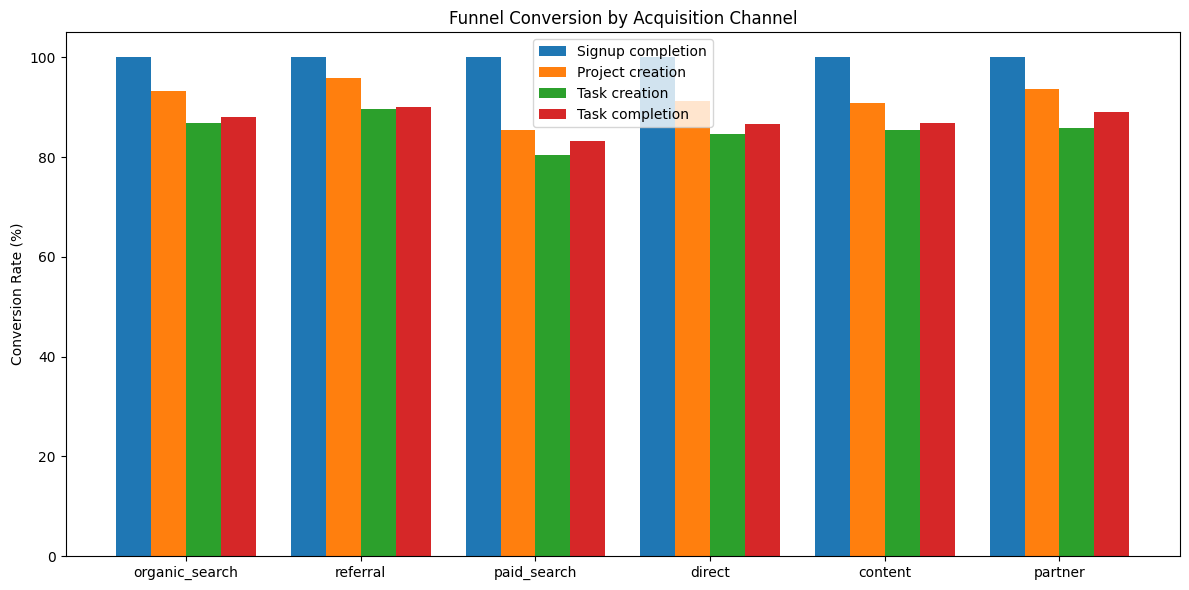

In [7]:
stages = {
    "signup_completion_conversion_rate_pct": "Signup completion",
    "project_creation_conversion_rate_pct": "Project creation",
    "task_creation_conversion_rate_pct": "Task creation",
    "task_completion_conversion_rate_pct": "Task completion"
}

x = np.arange(len(funnel))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))

for i, (column, label) in enumerate(stages.items()):
    ax.bar(
        x + (i - 1.5) * width,
        funnel[column],
        width,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(funnel["acquisition_channel"])
ax.set_ylabel("Conversion Rate (%)")
ax.set_title("Funnel Conversion by Acquisition Channel")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
experiment = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.mart_experiment_impact`
    ORDER BY experiment_id, variant, outcome_event
""").to_dataframe()

display(experiment)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,experiment_id,experiment_name,variant,outcome_event,assigned_users,users_with_outcome_7d,outcome_rate_pct
0,EXP001,onboarding_redesign,new_onboarding,onboarding_step_completed,19665,13284,67.55
1,EXP001,onboarding_redesign,old_onboarding,onboarding_step_completed,19753,13299,67.33
2,EXP002,collaboration_prompt,no_prompt,invite_accepted,15673,1356,8.65
3,EXP002,collaboration_prompt,no_prompt,invite_sent,15673,2247,14.34
4,EXP002,collaboration_prompt,prompt_shown,invite_accepted,15835,1653,10.44
5,EXP002,collaboration_prompt,prompt_shown,invite_sent,15835,2348,14.83


In [9]:
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests

comparisons = [
    ("EXP001", "onboarding_step_completed", "new_onboarding", "old_onboarding"),
    ("EXP002", "invite_sent", "prompt_shown", "no_prompt"),
    ("EXP002", "invite_accepted", "prompt_shown", "no_prompt")
]

results = []

for exp_id, outcome, treatment, control in comparisons:

    t = experiment[
        (experiment["experiment_id"] == exp_id) &
        (experiment["outcome_event"] == outcome) &
        (experiment["variant"] == treatment)
    ].iloc[0]

    c = experiment[
        (experiment["experiment_id"] == exp_id) &
        (experiment["outcome_event"] == outcome) &
        (experiment["variant"] == control)
    ].iloc[0]

    t_users = int(t["users_with_outcome_7d"])
    t_total = int(t["assigned_users"])

    c_users = int(c["users_with_outcome_7d"])
    c_total = int(c["assigned_users"])

    t_rate = t_users / t_total
    c_rate = c_users / c_total

    absolute_lift = (t_rate - c_rate) * 100
    relative_lift = ((t_rate - c_rate) / c_rate) * 100

    _, p_value = proportions_ztest(
        [t_users, c_users],
        [t_total, c_total]
    )

    ci_low, ci_high = confint_proportions_2indep(
        t_users,
        t_total,
        c_users,
        c_total,
        method="newcomb"
    )

    results.append({
        "experiment": exp_id,
        "outcome": outcome,
        "control_rate_pct": c_rate * 100,
        "treatment_rate_pct": t_rate * 100,
        "absolute_lift_pp": absolute_lift,
        "relative_lift_pct": relative_lift,
        "ci_lower_pp": ci_low * 100,
        "ci_upper_pp": ci_high * 100,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["adjusted_p_value"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = results_df["adjusted_p_value"] < 0.05

display(results_df.round(5))

,experiment,outcome,control_rate_pct,treatment_rate_pct,absolute_lift_pp,relative_lift_pct,ci_lower_pp,ci_upper_pp,p_value,adjusted_p_value,significant
0,EXP001,onboarding_step_completed,67.32648,67.55149,0.22501,0.33420,-0.70017,1.15009,0.63361,0.63361,False
1,EXP002,invite_sent,14.33676,14.82791,0.49116,3.42585,-0.28839,1.27051,0.21681,0.43361,False
2,EXP002,invite_accepted,8.65182,10.43890,1.78708,20.65553,1.13856,2.43594,0.00000,0.00000,True


c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,company_size,total_users,eligible_users,activated_users,activation_rate_pct
0,11-50,19714,19714,7204,36.54
1,51-200,12454,12454,4944,39.70
2,1-10,12403,12403,3828,30.86
3,201-1000,5429,5429,2189,40.32


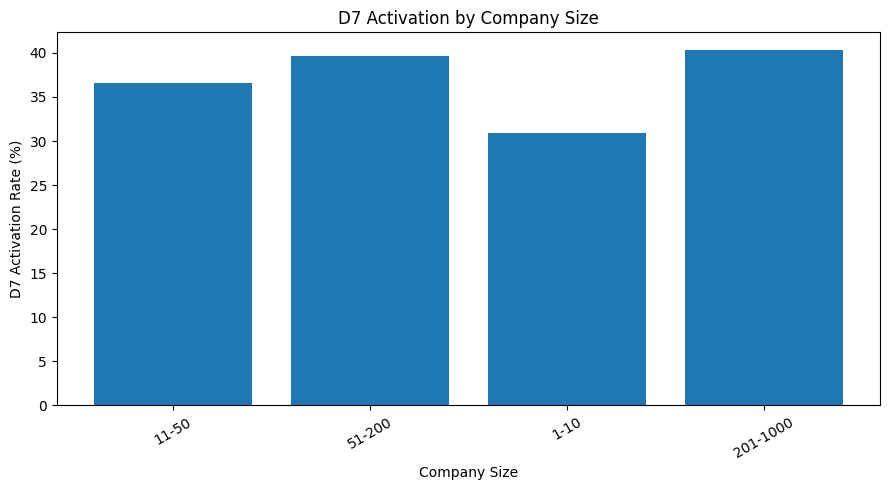

In [10]:
company_segments = client.query("""
    SELECT
        COALESCE(company_size, 'Unknown') AS company_size,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7 IS NOT NULL) AS eligible_users,
        COUNTIF(activated_d7 IS TRUE) AS activated_users,
        ROUND(
            SAFE_DIVIDE(
                COUNTIF(activated_d7 IS TRUE),
                COUNTIF(activated_d7 IS NOT NULL)
            ) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(company_segments)

plt.figure(figsize=(9, 5))
plt.bar(
    company_segments["company_size"],
    company_segments["activation_rate_pct"]
)
plt.xlabel("Company Size")
plt.ylabel("D7 Activation Rate (%)")
plt.title("D7 Activation by Company Size")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,role,total_users,eligible_users,activated_users,activation_rate_pct
0,member,25557,25557,9327,36.49
1,admin,17122,17122,6243,36.46
2,manager,7321,7321,2595,35.45


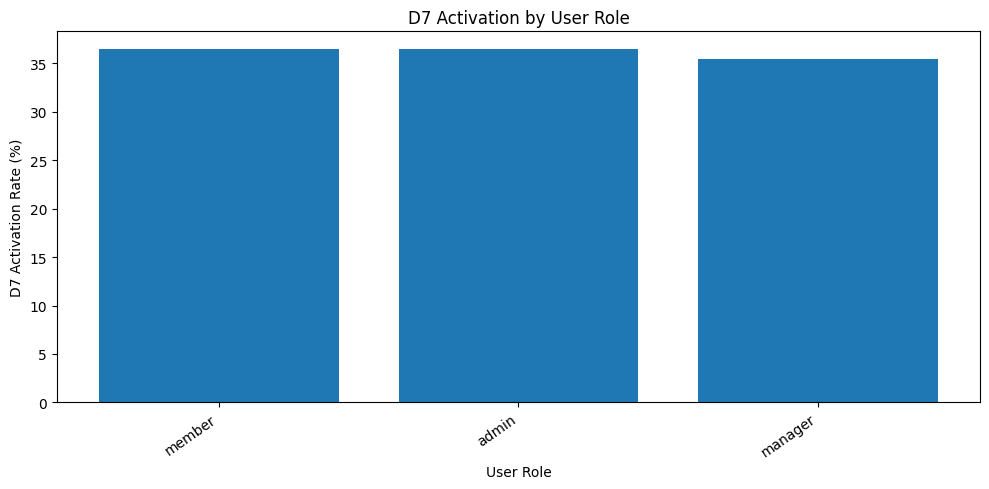

In [11]:
role_segments = client.query("""
    SELECT
        COALESCE(role, 'Unknown') AS role,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7 IS NOT NULL) AS eligible_users,
        COUNTIF(activated_d7 IS TRUE) AS activated_users,
        ROUND(
            SAFE_DIVIDE(
                COUNTIF(activated_d7 IS TRUE),
                COUNTIF(activated_d7 IS NOT NULL)
            ) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(role_segments)

plt.figure(figsize=(10, 5))
plt.bar(role_segments["role"], role_segments["activation_rate_pct"])
plt.ylabel("D7 Activation Rate (%)")
plt.xlabel("User Role")
plt.title("D7 Activation by User Role")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,device_type,total_users,eligible_users,activated_users,activation_rate_pct
0,desktop,36040,36040,13103,36.36
1,mobile,11931,11931,4350,36.46
2,tablet,2029,2029,712,35.09


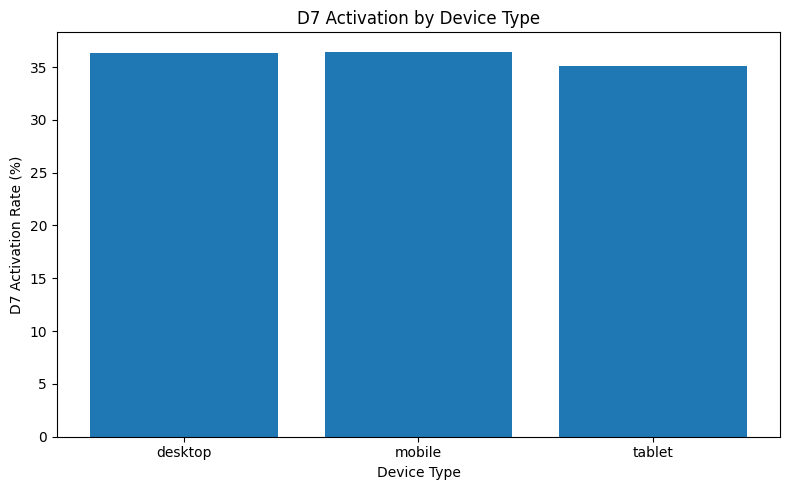

In [12]:
device_segments = client.query("""
    SELECT
        COALESCE(device_type, 'Unknown') AS device_type,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7 IS NOT NULL) AS eligible_users,
        COUNTIF(activated_d7 IS TRUE) AS activated_users,
        ROUND(
            SAFE_DIVIDE(
                COUNTIF(activated_d7 IS TRUE),
                COUNTIF(activated_d7 IS NOT NULL)
            ) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(device_segments)

plt.figure(figsize=(8, 5))
plt.bar(device_segments["device_type"], device_segments["activation_rate_pct"])
plt.ylabel("D7 Activation Rate (%)")
plt.xlabel("Device Type")
plt.title("D7 Activation by Device Type")
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,industry,total_users,eligible_users,activated_users,activation_rate_pct
0,technology,11492,11492,4190,36.46
1,professional_services,8531,8531,3126,36.64
2,education,5953,5953,2168,36.42
3,financial_services,5042,5042,1791,35.52
4,healthcare,4994,4994,1839,36.82
5,retail,4994,4994,1781,35.66
6,manufacturing,4914,4914,1783,36.28
7,media,4080,4080,1487,36.45


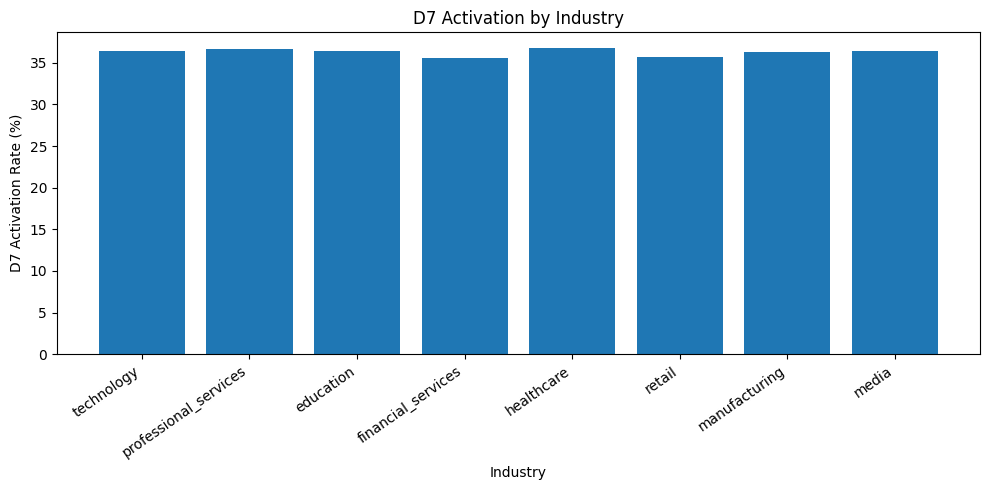

In [13]:
industry_segments = client.query("""
    SELECT
        COALESCE(industry, 'Unknown') AS industry,
        COUNT(*) AS total_users,
        COUNTIF(activated_d7 IS NOT NULL) AS eligible_users,
        COUNTIF(activated_d7 IS TRUE) AS activated_users,
        ROUND(
            SAFE_DIVIDE(
                COUNTIF(activated_d7 IS TRUE),
                COUNTIF(activated_d7 IS NOT NULL)
            ) * 100,
            2
        ) AS activation_rate_pct
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY total_users DESC
""").to_dataframe()

display(industry_segments)

plt.figure(figsize=(10, 5))
plt.bar(industry_segments["industry"], industry_segments["activation_rate_pct"])
plt.ylabel("D7 Activation Rate (%)")
plt.xlabel("Industry")
plt.title("D7 Activation by Industry")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [14]:
engagement = client.query("""
    SELECT
        IF(activated_d7, 'Activated', 'Not Activated') AS activation_status,
        COUNT(*) AS users,
        ROUND(AVG(active_days), 2) AS avg_active_days,
        ROUND(AVG(total_activity_events), 2) AS avg_activity_events,
        ROUND(AVG(total_sessions), 2) AS avg_sessions,
        ROUND(AVG(avg_session_duration_seconds), 2) AS avg_session_duration_seconds
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY 1
""").to_dataframe()

display(engagement)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,activation_status,users,avg_active_days,avg_activity_events,avg_sessions,avg_session_duration_seconds
0,Activated,18165,4.23,15.71,4.85,777.62
1,Not Activated,31835,2.86,8.37,3.76,777.29


In [15]:
engagement_distribution = client.query("""
    SELECT
        IF(activated_d7, 'Activated', 'Not Activated') AS activation_status,
        APPROX_QUANTILES(active_days, 100)[OFFSET(50)] AS median_active_days,
        APPROX_QUANTILES(total_activity_events, 100)[OFFSET(50)] AS median_activity_events,
        APPROX_QUANTILES(total_sessions, 100)[OFFSET(50)] AS median_sessions
    FROM `product-analysis-509809.saas_analytics_dbt.mart_user_metrics`
    GROUP BY 1
    ORDER BY 1
""").to_dataframe()

display(engagement_distribution)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,activation_status,median_active_days,median_activity_events,median_sessions
0,Activated,4,14,4
1,Not Activated,2,7,3


In [16]:
weighted_rows = []

for status, group in retention.groupby("activation_status"):
    row = {"activation_status": status}

    for day in ["d1", "d7", "d30"]:
        rate_col = f"{day}_retention_rate"
        retained_col = f"{day}_retained_users"

        eligible = group.loc[group[rate_col].notna()]
        eligible_users = eligible["cohort_users"].sum()
        retained_users = eligible[retained_col].sum()

        row[f"{day}_eligible_users"] = int(eligible_users)
        row[f"{day}_retained_users"] = int(retained_users)
        row[f"{day}_retention_pct"] = (
            round(retained_users / eligible_users * 100, 2)
            if eligible_users else np.nan
        )

    weighted_rows.append(row)

weighted_retention = pd.DataFrame(weighted_rows)
display(weighted_retention)

,activation_status,d1_eligible_users,d1_retained_users,d1_retention_pct,d7_eligible_users,d7_retained_users,d7_retention_pct,d30_eligible_users,d30_retained_users,d30_retention_pct
0,activated_d7,18165,2080,11.45,18165,1561,8.59,18165,441,2.43
1,not_activated_d7,31835,1033,3.24,31835,1354,4.25,31835,560,1.76


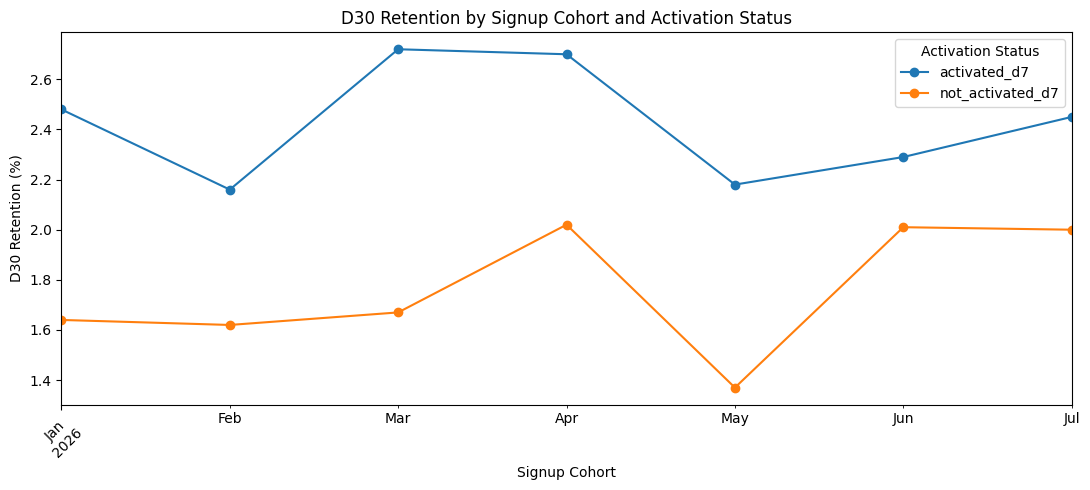

In [17]:
retention_plot = retention.pivot(
    index="signup_cohort_month",
    columns="activation_status",
    values="d30_retention_rate"
)

retention_plot.plot(figsize=(11, 5), marker="o")
plt.title("D30 Retention by Signup Cohort and Activation Status")
plt.xlabel("Signup Cohort")
plt.ylabel("D30 Retention (%)")
plt.xticks(rotation=45)
plt.legend(title="Activation Status")
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,week_start_date,weekly_task_completing_users,task_completion_events
0,2026-01-05,640,929
1,2026-01-12,861,1283
2,2026-01-19,1049,1561
3,2026-01-26,1182,1757
4,2026-02-02,1317,1923
5,2026-02-09,1407,2032
6,2026-02-16,1480,2185
7,2026-02-23,1613,2393
8,2026-03-02,1640,2370
9,2026-03-09,1723,2467


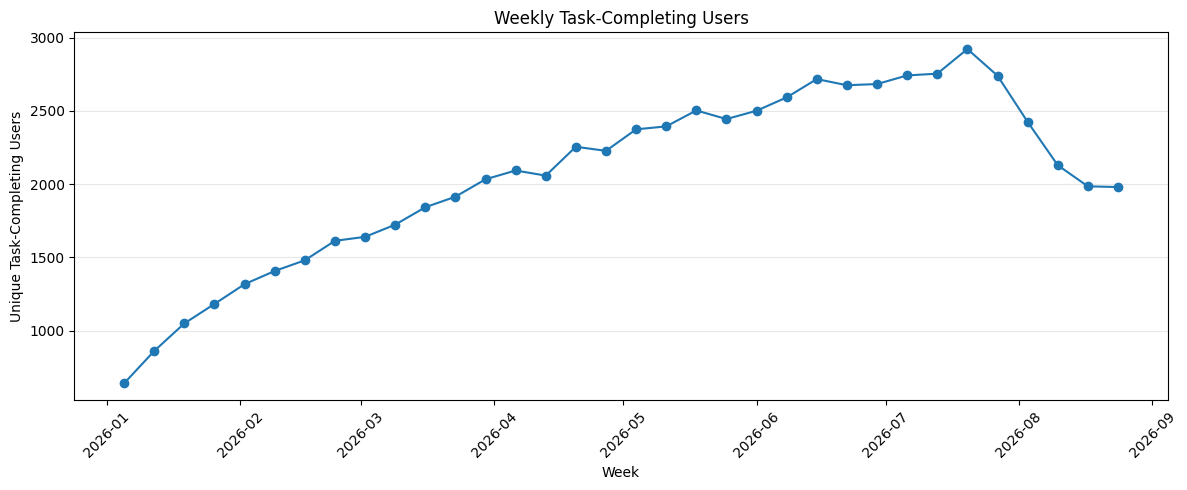

In [18]:
weekly = client.query("""
    SELECT
        week_start_date,
        weekly_task_completing_users,
        task_completion_events
    FROM `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users`
    WHERE is_complete_week = TRUE
    ORDER BY week_start_date
""").to_dataframe()

display(weekly)

plt.figure(figsize=(12, 5))
plt.plot(
    weekly["week_start_date"],
    weekly["weekly_task_completing_users"],
    marker="o"
)
plt.title("Weekly Task-Completing Users")
plt.xlabel("Week")
plt.ylabel("Unique Task-Completing Users")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


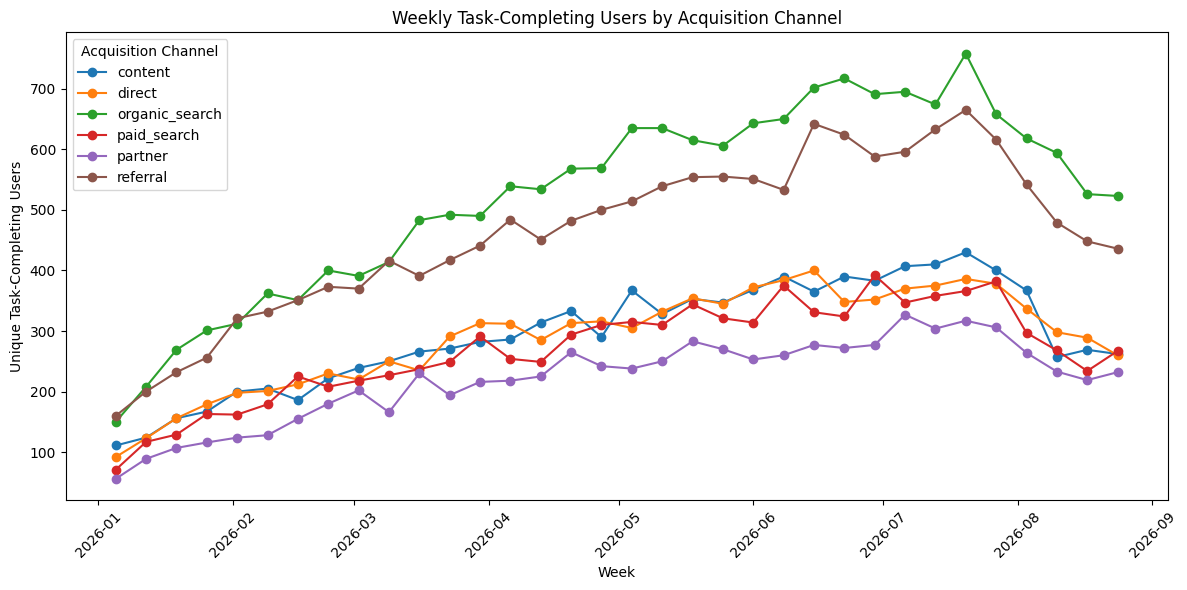

In [19]:
weekly_channels = client.query("""
    WITH task_completing_user_weeks AS (
        SELECT
            DATE_TRUNC(activity_date, WEEK(MONDAY)) AS week_start_date,
            user_id,
            MIN(activity_date) AS first_task_completion_date
        FROM `product-analysis-509809.saas_analytics_dbt.int_user_activity_daily`
        WHERE task_completion_event_count > 0
        GROUP BY 1, 2
    )

    SELECT
        w.week_start_date,
        CASE
            WHEN u.user_id IS NULL THEN 'Unmapped user'
            WHEN DATE(u.signup_timestamp, 'UTC') IS NULL
                 OR DATE(u.signup_timestamp, 'UTC') > a.first_task_completion_date
                THEN 'Pre-signup activity / invalid date'
            ELSE COALESCE(u.acquisition_channel, 'Unknown channel')
        END AS acquisition_channel,
        COUNT(*) AS weekly_task_completing_users
    FROM task_completing_user_weeks a
    JOIN `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users` w
        ON a.week_start_date = w.week_start_date
    LEFT JOIN `product-analysis-509809.saas_analytics_dbt.stg_users` u
        USING (user_id)
    WHERE w.is_complete_week = TRUE
    GROUP BY 1, 2
    ORDER BY 1, 2
""").to_dataframe()

channel_pivot = weekly_channels.pivot(
    index="week_start_date",
    columns="acquisition_channel",
    values="weekly_task_completing_users"
).fillna(0)

channel_pivot.plot(figsize=(12, 6), marker="o")
plt.title("Weekly Task-Completing Users by Acquisition Channel")
plt.xlabel("Week")
plt.ylabel("Unique Task-Completing Users")
plt.legend(title="Acquisition Channel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,week_start_date,new_active_users,existing_active_users,unclassified_activity_users
0,2026-01-05,491,149,0
1,2026-01-12,487,374,0
2,2026-01-19,506,543,0
3,2026-01-26,500,682,0
4,2026-02-02,508,809,0
5,2026-02-09,491,916,0
6,2026-02-16,527,953,0
7,2026-02-23,525,1088,0
8,2026-03-02,509,1131,0
9,2026-03-09,489,1234,0


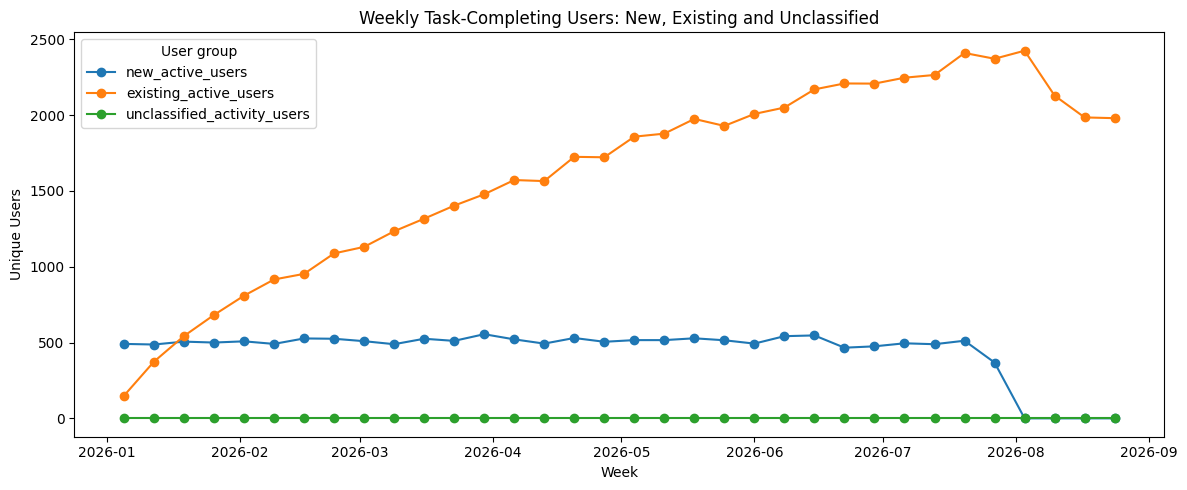

In [20]:
weekly_user_mix = client.query("""
    WITH task_completing_user_weeks AS (
        SELECT
            DATE_TRUNC(activity_date, WEEK(MONDAY)) AS week_start_date,
            user_id,
            MIN(activity_date) AS first_task_completion_date
        FROM `product-analysis-509809.saas_analytics_dbt.int_user_activity_daily`
        WHERE task_completion_event_count > 0
        GROUP BY 1, 2
    )

    SELECT
        w.week_start_date,

        COUNTIF(
            u.user_id IS NOT NULL
            AND DATE(u.signup_timestamp, 'UTC') IS NOT NULL
            AND DATE(u.signup_timestamp, 'UTC')
                BETWEEN w.week_start_date AND w.week_end_date
            AND DATE(u.signup_timestamp, 'UTC') <= a.first_task_completion_date
        ) AS new_active_users,

        COUNTIF(
            u.user_id IS NOT NULL
            AND DATE(u.signup_timestamp, 'UTC') < w.week_start_date
            AND DATE(u.signup_timestamp, 'UTC') <= a.first_task_completion_date
        ) AS existing_active_users,

        COUNTIF(
            u.user_id IS NULL
            OR DATE(u.signup_timestamp, 'UTC') IS NULL
            OR DATE(u.signup_timestamp, 'UTC') > a.first_task_completion_date
        ) AS unclassified_activity_users

    FROM task_completing_user_weeks a
    JOIN `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users` w
        ON a.week_start_date = w.week_start_date
    LEFT JOIN `product-analysis-509809.saas_analytics_dbt.stg_users` u
        USING (user_id)
    WHERE w.is_complete_week = TRUE
    GROUP BY 1
    ORDER BY 1
""").to_dataframe()

display(weekly_user_mix)

weekly_user_mix.set_index("week_start_date")[
    ["new_active_users", "existing_active_users", "unclassified_activity_users"]
].plot(figsize=(12, 5), marker="o")

plt.title("Weekly Task-Completing Users: New, Existing and Unclassified")
plt.ylabel("Unique Users")
plt.xlabel("Week")
plt.legend(title="User group")
plt.tight_layout()
plt.show()

In [21]:
weekly_signups = client.query("""
    SELECT
        DATE_TRUNC(DATE(signup_timestamp, 'UTC'), WEEK(MONDAY)) AS week_start,
        COUNT(DISTINCT user_id) AS new_signups
    FROM `product-analysis-509809.saas_analytics_dbt.stg_users`
    GROUP BY 1
    ORDER BY 1
""").to_dataframe()

display(weekly_signups)

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,week_start,new_signups
0,2025-12-29,973
1,2026-01-05,1621
2,2026-01-12,1599
3,2026-01-19,1674
4,2026-01-26,1664
5,2026-02-02,1690
6,2026-02-09,1607
7,2026-02-16,1692
8,2026-02-23,1669
9,2026-03-02,1656


,stage,users,users_lost_from_previous_stage,conversion_from_previous_stage_pct,conversion_from_signup_pct
0,Total Signups,50000,0,NaN,100.00
1,Signup Completed,50000,0,100.00,100.00
2,Project Created,45828,4172,91.66,91.66
3,Task Created,39259,6569,85.67,78.52
4,Task Completed,34323,4936,87.43,68.65


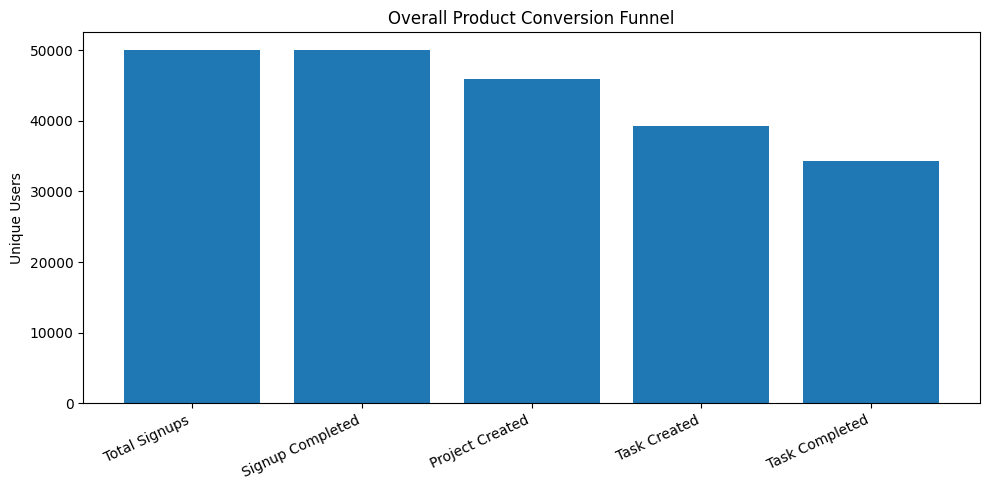

In [22]:
funnel_stages = [
    ("Total Signups", "total_signups"),
    ("Signup Completed", "signup_completed_users"),
    ("Project Created", "project_created_users"),
    ("Task Created", "task_created_users"),
    ("Task Completed", "task_completed_users")
]

funnel_rows = []
previous_users = None
total_signups = int(funnel["total_signups"].sum())

for stage, column in funnel_stages:
    users = int(funnel[column].sum())

    funnel_rows.append({
        "stage": stage,
        "users": users,
        "users_lost_from_previous_stage": (
            previous_users - users if previous_users is not None else 0
        ),
        "conversion_from_previous_stage_pct": (
            round(users / previous_users * 100, 2)
            if previous_users else np.nan
        ),
        "conversion_from_signup_pct": round(users / total_signups * 100, 2)
        if total_signups else np.nan
    })

    previous_users = users

funnel_totals = pd.DataFrame(funnel_rows)
display(funnel_totals)

plt.figure(figsize=(10, 5))
plt.bar(funnel_totals["stage"], funnel_totals["users"])
plt.title("Overall Product Conversion Funnel")
plt.ylabel("Unique Users")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Additional Diagnostics and Robustness Checks

The following analyses test whether segment differences are statistically meaningful, examine weekly task-completion participation by signup cohort, check source-data coverage, and reconcile the WTCU trend. Run these after the preceding cells.

In [23]:

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

segment_frames = {
    "Company Size": company_segments,
    "Role": role_segments,
    "Device Type": device_segments,
    "Industry": industry_segments
}

segment_results = []

for dimension, df in segment_frames.items():
    eligible_users = df["eligible_users"].astype(int)
    activated_users = df["activated_users"].astype(int)
    not_activated_users = eligible_users - activated_users

    contingency = np.column_stack([
        activated_users,
        not_activated_users
    ])

    chi2, p_value, _, _ = chi2_contingency(contingency)
    n = contingency.sum()
    min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (n * min_dimension)) if min_dimension > 0 and n > 0 else np.nan

    segment_results.append({
        "dimension": dimension,
        "categories": len(df),
        "eligible_users": int(n),
        "chi_square": chi2,
        "p_value": p_value,
        "cramers_v": cramers_v
    })

segment_tests = pd.DataFrame(segment_results)
segment_tests["holm_adjusted_p"] = multipletests(
    segment_tests["p_value"],
    method="holm"
)[1]

segment_tests = segment_tests.sort_values("holm_adjusted_p")
display(segment_tests.round(5))


,dimension,categories,eligible_users,chi_square,p_value,cramers_v,holm_adjusted_p
0,Company Size,4,50000,259.06666,0.00000,0.07198,0.00000
1,Role,3,50000,2.90253,0.23427,0.00762,0.70282
2,Device Type,3,50000,1.44407,0.48576,0.00537,0.97152
3,Industry,8,50000,3.40631,0.84505,0.00825,0.97152


### Signup Cohort Activity

This heatmap measures the percentage of each signup cohort completing at least one task in each subsequent complete week. It is a weekly activity measure, not the same metric as D1/D7/D30 retention.

c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,signup_week,activity_week,weeks_since_signup,cohort_users,task_completing_users,weekly_task_completion_rate_pct
0,2025-12-29,2026-01-05,1,973,149,15.31
1,2025-12-29,2026-01-12,2,973,126,12.95
2,2025-12-29,2026-01-19,3,973,70,7.19
3,2025-12-29,2026-01-26,4,973,69,7.09
4,2025-12-29,2026-02-02,5,973,69,7.09
5,2025-12-29,2026-02-09,6,973,61,6.27
6,2025-12-29,2026-02-16,7,973,51,5.24
7,2025-12-29,2026-02-23,8,973,54,5.55
8,2025-12-29,2026-03-02,9,973,51,5.24
9,2025-12-29,2026-03-09,10,973,59,6.06


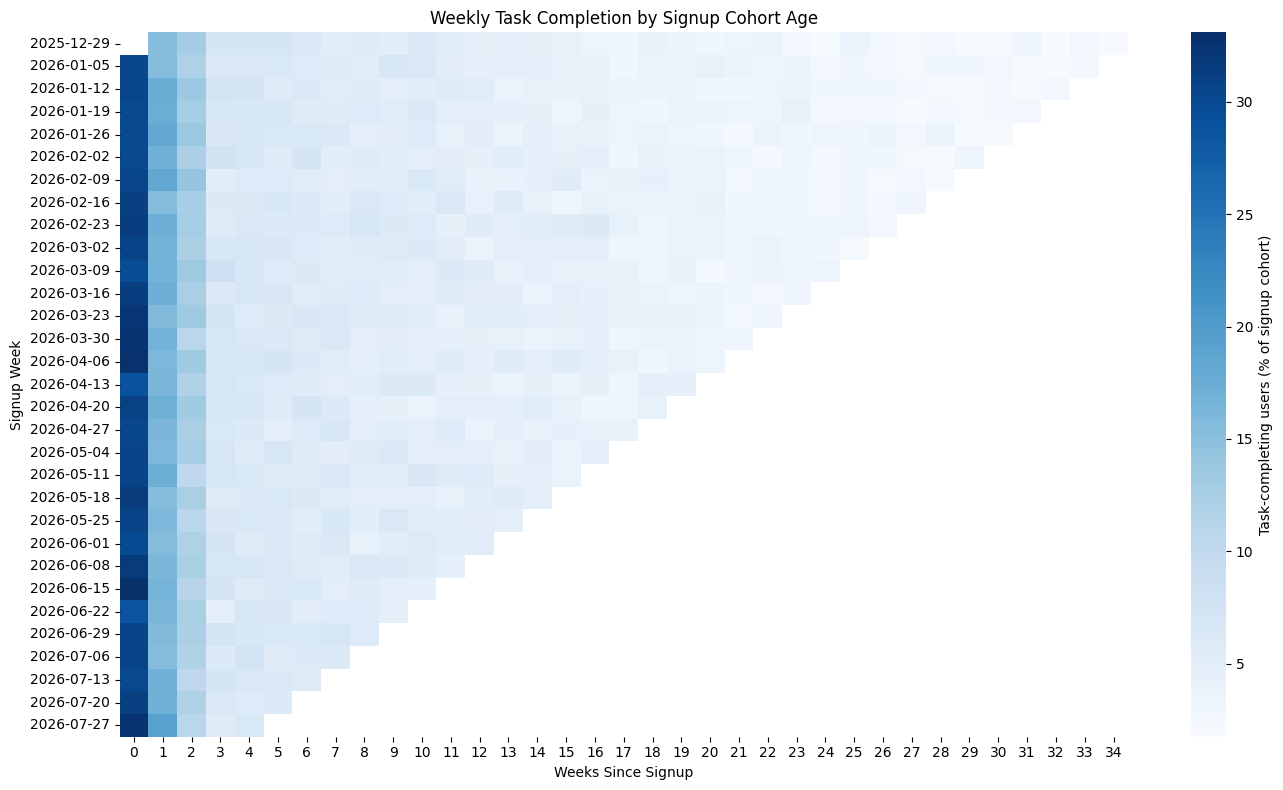

In [24]:

cohort_activity = client.query("""
    WITH user_cohorts AS (
        SELECT
            user_id,
            DATE(signup_timestamp, 'UTC') AS signup_date,
            DATE_TRUNC(DATE(signup_timestamp, 'UTC'), WEEK(MONDAY)) AS signup_week
        FROM `product-analysis-509809.saas_analytics_dbt.stg_users`
    ),

    cohort_sizes AS (
        SELECT
            signup_week,
            COUNT(DISTINCT user_id) AS cohort_users
        FROM user_cohorts
        GROUP BY 1
    ),

    cohort_weeks AS (
        SELECT
            c.signup_week,
            w.week_start_date AS activity_week,
            DATE_DIFF(w.week_start_date, c.signup_week, WEEK(MONDAY)) AS weeks_since_signup,
            c.cohort_users
        FROM cohort_sizes c
        JOIN `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users` w
            ON w.week_start_date >= c.signup_week
        WHERE w.is_complete_week = TRUE
    ),

    activity_counts AS (
        SELECT
            c.signup_week,
            DATE_TRUNC(a.activity_date, WEEK(MONDAY)) AS activity_week,
            COUNT(DISTINCT a.user_id) AS task_completing_users
        FROM `product-analysis-509809.saas_analytics_dbt.int_user_activity_daily` a
        JOIN user_cohorts c USING (user_id)
        JOIN `product-analysis-509809.saas_analytics_dbt.mart_weekly_task_completing_users` w
            ON DATE_TRUNC(a.activity_date, WEEK(MONDAY)) = w.week_start_date
        WHERE w.is_complete_week = TRUE
          AND a.task_completion_event_count > 0
          AND a.activity_date >= c.signup_date
        GROUP BY 1, 2
    )

    SELECT
        c.signup_week,
        c.activity_week,
        c.weeks_since_signup,
        c.cohort_users,
        COALESCE(a.task_completing_users, 0) AS task_completing_users,
        ROUND(
            SAFE_DIVIDE(COALESCE(a.task_completing_users, 0), c.cohort_users) * 100,
            2
        ) AS weekly_task_completion_rate_pct
    FROM cohort_weeks c
    LEFT JOIN activity_counts a
        USING (signup_week, activity_week)
    ORDER BY 1, 3
""").to_dataframe()

display(cohort_activity.head(20))

cohort_matrix = cohort_activity.pivot(
    index="signup_week",
    columns="weeks_since_signup",
    values="weekly_task_completion_rate_pct"
)

plt.figure(figsize=(14, 8))
sns.heatmap(
    cohort_matrix,
    cmap="Blues",
    annot=False,
    cbar_kws={"label": "Task-completing users (% of signup cohort)"}
)
plt.title("Weekly Task Completion by Signup Cohort Age")
plt.xlabel("Weeks Since Signup")
plt.ylabel("Signup Week")
plt.tight_layout()
plt.show()


### Source Coverage and Product-Change Checks

The signup table appears to stop earlier than the task-activity series. Establish the observed date ranges before interpreting the new-user component of WTCU. The product-change log is also inspected for changes that could be compared with the decline window; temporal overlap alone will not prove causation.

In [25]:

source_coverage = client.query("""
    SELECT
        'users' AS source,
        COUNT(*) AS row_count,
        MIN(DATE(signup_timestamp, 'UTC')) AS first_date,
        MAX(DATE(signup_timestamp, 'UTC')) AS last_date
    FROM `product-analysis-509809.saas_analytics_dbt.stg_users`

    UNION ALL

    SELECT
        'events',
        COUNT(*),
        MIN(DATE(event_at, 'UTC')),
        MAX(DATE(event_at, 'UTC'))
    FROM `product-analysis-509809.saas_analytics_dbt.stg_events`
""").to_dataframe()

display(source_coverage)


c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,source,row_count,first_date,last_date
0,users,50000,2026-01-01,2026-07-31
1,events,1473869,2026-01-01,2026-08-31


In [26]:

product_changes_schema = client.query("""
    SELECT
        column_name,
        data_type
    FROM `product-analysis-509809.saas_analytics_dbt.INFORMATION_SCHEMA.COLUMNS`
    WHERE table_name = 'stg_product_changes'
    ORDER BY ordinal_position
""").to_dataframe()

product_changes = client.query("""
    SELECT *
    FROM `product-analysis-509809.saas_analytics_dbt.stg_product_changes`
    ORDER BY 1
""").to_dataframe()

display(product_changes_schema)
display(product_changes)


c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(
c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,column_name,data_type
0,change_id,STRING
1,change_name,STRING
2,change_type,STRING
3,release_date,TIMESTAMP
4,affected_feature,STRING
5,description,STRING
6,loaded_at,TIMESTAMP


,change_id,change_name,change_type,release_date,affected_feature,description,loaded_at
0,CHG001,Onboarding checklist redesign,onboarding,2026-02-15 00:00:00+00:00,onboarding,Reorganized onboarding into shorter task-orien...,2026-11-26 07:02:58.055308+00:00
1,CHG002,Collaboration comments v2,collaboration,2026-03-20 00:00:00+00:00,comments,Introduced threaded comments and mention notif...,2026-11-26 07:02:58.055308+00:00
2,CHG003,Project template discovery,discovery,2026-04-10 00:00:00+00:00,templates,Added recommended templates during project cre...,2026-11-26 07:02:58.055308+00:00
3,CHG004,Notification preference center,engagement,2026-05-05 00:00:00+00:00,notifications,Allowed users to customize notification freque...,2026-11-26 07:02:58.055308+00:00
4,CHG005,Team invite flow simplification,collaboration,2026-06-01 00:00:00+00:00,invites,Reduced friction in inviting teammates to a wo...,2026-11-26 07:02:58.055308+00:00


In [27]:

task_user_coverage = client.query("""
    WITH task_completing_users AS (
        SELECT DISTINCT user_id
        FROM `product-analysis-509809.saas_analytics_dbt.int_user_activity_daily`
        WHERE task_completion_event_count > 0
    )

    SELECT
        COUNT(*) AS task_completing_users,
        COUNTIF(u.user_id IS NOT NULL) AS matched_to_user_dimension,
        COUNTIF(u.user_id IS NULL) AS unmatched_to_user_dimension
    FROM task_completing_users t
    LEFT JOIN `product-analysis-509809.saas_analytics_dbt.stg_users` u
        USING (user_id)
""").to_dataframe()

display(task_user_coverage)


c:\Users\Hima\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,task_completing_users,matched_to_user_dimension,unmatched_to_user_dimension
0,34334,34334,0


### WTCU Decline: Reconciliation and Interpretation

This compares the peak and latest complete weeks. The new-user component is only interpretable when the signup table covers the full week being classified. Unmapped or pre-signup task activity is kept separate rather than silently discarded.

In [28]:

weekly_diagnostic = weekly.merge(
    weekly_user_mix,
    on="week_start_date",
    how="left",
    validate="one_to_one"
)

component_columns = [
    "new_active_users",
    "existing_active_users",
    "unclassified_activity_users"
]
weekly_diagnostic[component_columns] = weekly_diagnostic[component_columns].fillna(0)

weekly_diagnostic["reconstructed_wtcu"] = weekly_diagnostic[component_columns].sum(axis=1)
weekly_diagnostic["reconciliation_difference"] = (
    weekly_diagnostic["weekly_task_completing_users"]
    - weekly_diagnostic["reconstructed_wtcu"]
)

user_last_date = pd.to_datetime(
    source_coverage.loc[source_coverage["source"] == "users", "last_date"].iloc[0]
).normalize()

weekly_diagnostic["week_end_date"] = (
    pd.to_datetime(weekly_diagnostic["week_start_date"])
    + pd.Timedelta(days=6)
)
weekly_diagnostic["signup_dimension_covers_full_week"] = (
    weekly_diagnostic["week_end_date"] <= user_last_date
)

print("Latest signup date in user dimension:", user_last_date.date())
print("Latest complete WTCU week:", pd.to_datetime(weekly_diagnostic["week_start_date"].max()).date())
print("Maximum absolute WTCU reconciliation difference:",
      int(weekly_diagnostic["reconciliation_difference"].abs().max()))

display(weekly_diagnostic[[
    "week_start_date",
    "weekly_task_completing_users",
    "new_active_users",
    "existing_active_users",
    "unclassified_activity_users",
    "reconciliation_difference",
    "signup_dimension_covers_full_week"
]])

peak = weekly_diagnostic.loc[
    weekly_diagnostic["weekly_task_completing_users"].idxmax()
]
latest = weekly_diagnostic.iloc[-1]

comparison_rows = []
for metric, label in [
    ("weekly_task_completing_users", "Total WTCU"),
    ("new_active_users", "New task-completing users"),
    ("existing_active_users", "Existing task-completing users"),
    ("unclassified_activity_users", "Unclassified task-completing users")
]:
    peak_value = int(peak[metric])
    latest_value = int(latest[metric])
    pct_change = (
        round((latest_value - peak_value) / peak_value * 100, 2)
        if peak_value else np.nan
    )

    note = "Observed comparison"
    if metric == "new_active_users" and not bool(latest["signup_dimension_covers_full_week"]):
        pct_change = np.nan
        note = "Not interpretable: signup records do not cover the latest full week"
    elif metric == "unclassified_activity_users":
        note = "Check user-dimension join and pre-signup event quality"
    elif metric == "existing_active_users":
        note = "Existing users identifiable in the available signup table"

    comparison_rows.append({
        "metric": label,
        "peak_week": peak["week_start_date"],
        "peak_value": peak_value,
        "latest_week": latest["week_start_date"],
        "latest_value": latest_value,
        "change": latest_value - peak_value,
        "change_pct": pct_change,
        "interpretation": note
    })

decline_comparison = pd.DataFrame(comparison_rows)
display(decline_comparison)

if not bool(latest["signup_dimension_covers_full_week"]):
    print(
        "WARNING: The signup table ends before the latest WTCU week is complete. "
        "Do not interpret zero new active users in that week as zero real-world acquisition."
    )


Latest signup date in user dimension: 2026-07-31
Latest complete WTCU week: 2026-08-24
Maximum absolute WTCU reconciliation difference: 0


,week_start_date,weekly_task_completing_users,new_active_users,existing_active_users,unclassified_activity_users,reconciliation_difference,signup_dimension_covers_full_week
0,2026-01-05,640,491,149,0,0,True
1,2026-01-12,861,487,374,0,0,True
2,2026-01-19,1049,506,543,0,0,True
3,2026-01-26,1182,500,682,0,0,True
4,2026-02-02,1317,508,809,0,0,True
5,2026-02-09,1407,491,916,0,0,True
6,2026-02-16,1480,527,953,0,0,True
7,2026-02-23,1613,525,1088,0,0,True
8,2026-03-02,1640,509,1131,0,0,True
9,2026-03-09,1723,489,1234,0,0,True


,metric,peak_week,peak_value,latest_week,latest_value,change,change_pct,interpretation
0,Total WTCU,2026-07-20,2922,2026-08-24,1980,-942,-32.24,Observed comparison
1,New task-completing users,2026-07-20,512,2026-08-24,0,-512,NaN,Not interpretable: signup records do not cover...
2,Existing task-completing users,2026-07-20,2410,2026-08-24,1980,-430,-17.84,Existing users identifiable in the available s...
3,Unclassified task-completing users,2026-07-20,0,2026-08-24,0,0,NaN,Check user-dimension join and pre-signup event...
